# Robot Learning
## Exercise 1

2026
TAs: Andrea Protopapa (andrea.protopapa@polito.it), Davide Buoso (davide.buoso@polito.it)

# 1. Introduction
Throughout this exercise session, we will take a first look at a Reinforcement Learning environment and its components. In particular, we will deal with the Cart-Pole environment, a classic problem in Reinforcement Learning. Our primary goal is to implement and evaluate various control strategies, including a Linear Quadratic Regulator (LQR) baseline or random policies, to understand their impact on the system's performance and learn about the fundamental concepts of Reinforcement Learning, laying the groundwork for more advanced reinforcement learning techniques in subsequent exercises.

To proceed with the assignment, visit the dedicated starting code at the dedicated webpage and follow the steps listed below in this document. Note: if you haven’t joined the course’s github classroom yet, you will be asked to select your name when you visit it the first time.

As you follow the steps in this document, make sure you’re able to answer all the guiding questions listed at the end of each step.


# 2. Cartpole Gym environment: states, observations

The Cartpole environment consists of a cart and a pole mounted on top of it, as shown in Figure 1. The cart can move either to the left or to the right. The goal is to balance the pole in a vertical position in order to prevent it from falling down. The cart should also stay within a limited distance from the center (trying to move outside screen boundaries is considered a failure).
The observation is a four element vector:





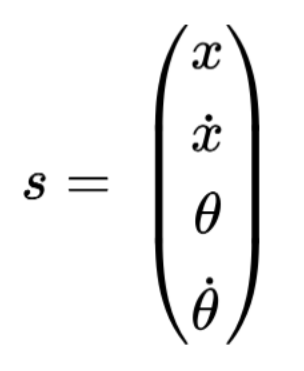

where  is the position of the cart,  is its velocity,  is the angle of the pole w.r.t. the vertical axis, and  is
the angular velocity of the pole.

Gym environment documentation:  https://gymnasium.farama.org/environments/classic_control/cart_pole/


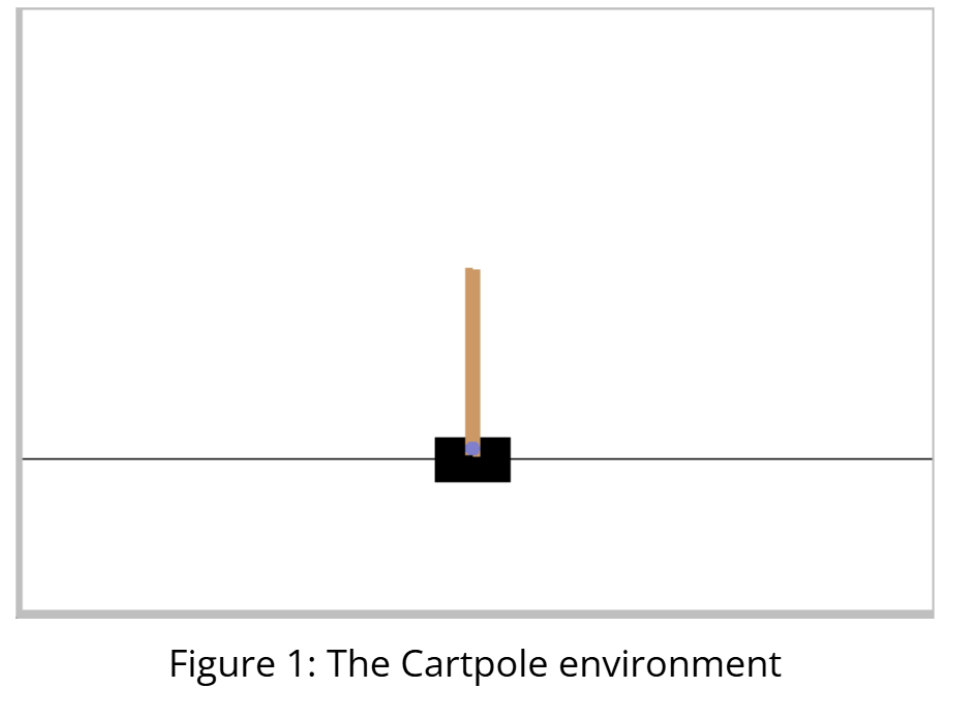

# 3. LQR
For the first assignment, you are tasked with testing a baseline using a Linear Quadratic Regulator (LQR), resulting in an optimal control gain K. The baseline is already implemented in the provided Python script (cartpole_lqr.py). Since the system exhibits nonlinear dynamics, a linear approximation of the system is available through the linearized_cartpole_system(...) function. Given the linear state space representation, the controller K is optimized by minimizing the following cost function:

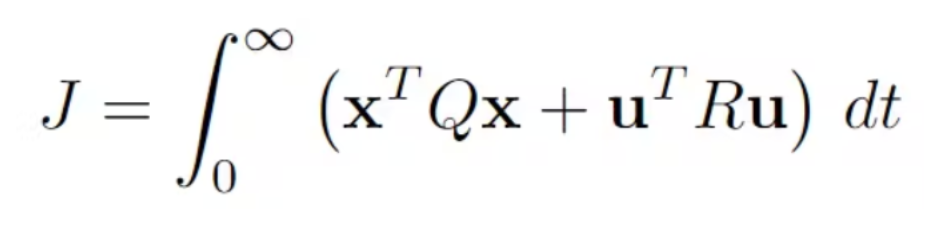

where Q and R are weight matrices carefully chosen and designed. The Q matrix represents the gain of the cost function on the states of the system, while the R matrix represents the gain of the cost function on the input to the system. Therefore, Q and R define what we consider as optimal.



## Task 1
Plot the states of the system (i.e., the elements of the observation vector) over the first 1000 timesteps. Remember that the Cart-Pole task is considered solved by Gym when 499 time steps are reached without the pole falling over.



In [1]:
import os
import cartpole_lqr
import numpy as np
import matplotlib.pyplot as plt

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
args = cartpole_lqr.parse_args([])

states = cartpole_lqr.main(args) 

Environment: CartPole-v1
Observation space dimensions: 4
Action space dimensions: 2
Episode ended after 1000 total iterations.


c:\Users\roc20\.conda\envs\conda_env\Lib\site-packages\gymnasium\envs\registration.py:732: UserWarning: WARN: The environment is being initialised with render_mode='None' that is not in the possible render_modes (['human', 'rgb_array']).
  logger.warn(


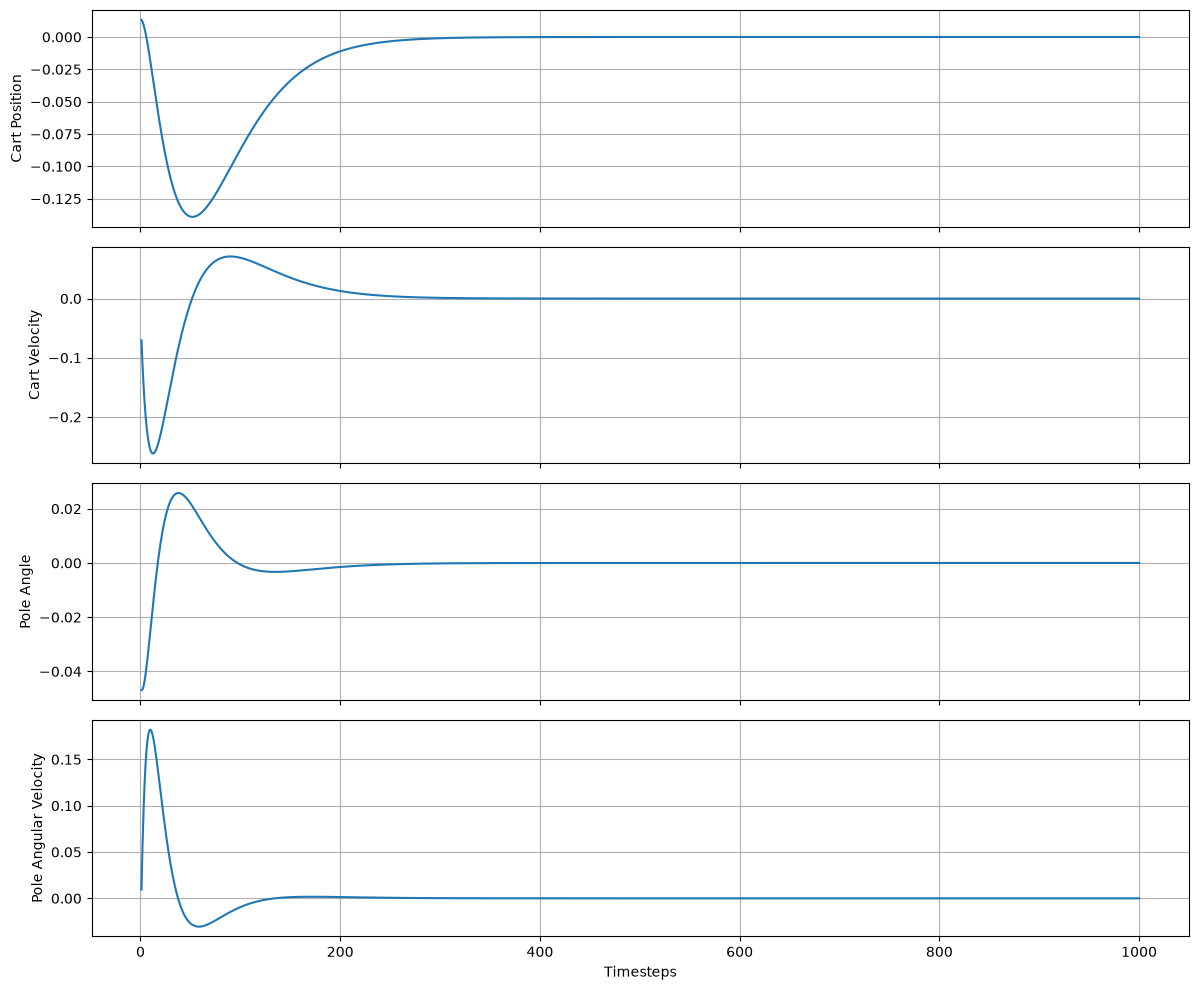

In [3]:
states = np.array(states)
timesteps = np.arange(1, len(states) + 1)

labels = [
    "Cart Position",
    "Cart Velocity",
    "Pole Angle",
    "Pole Angular Velocity"
]

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for i in range(4):
    axes[i].plot(timesteps, states[:, i])
    axes[i].set_ylabel(labels[i])
    axes[i].grid()

axes[-1].set_xlabel("Timesteps")

plt.tight_layout()
plt.show()

### Question 1  
Looking at the plot, after which timestep do all states converge to within 0 ± 0.003? Explain what it means for all states to converge to zero from a control standpoint.

### Answer 1:

In [4]:
tolerance = 0.003
window = 20

# First episode
for time in range(0, 1000 - window + 1):
    if np.all(np.abs(states[time:time+window]) < tolerance):
        print(f"Episode 1 - Time of convergence: {time}")
        break

Episode 1 - Time of convergence: 262


It means the the the cart is stationary at its reference position, with the pole perfectly balanced vertically. The controller successfullly stabilized the objects in their desired equilibrium.

## Task 2:
Vary the value of R within the range [0.01, 0.1, 10, 100] and plot the forces applied to each of the four controlled systems in a single graph over the first 500 timesteps.

*Note 1: for a better visual comparison, invert the single plot for each value of R if the first force applied on the cartpole is positive (e.g., if you are storing all the forces in an array called forces,
this means forces[0]>0). In this way, all the plots would have the same trend*.

Note 2: To ensure the experiments are comparable, you should recreate the environment for each R value. Otherwise, before resetting the environment, reset the seed.

```
		set_seed(args.seed) # seed for reproducibility
		env.env.seed(args.seed)
		# …
		env.reset()
```



Environment: CartPole-v1
Observation space dimensions: 4
Action space dimensions: 2
R = 0.01: Episode ended at timestep 500
R = 0.1: Episode ended at timestep 500
R = 10: Episode ended at timestep 500
R = 100: Episode ended at timestep 500


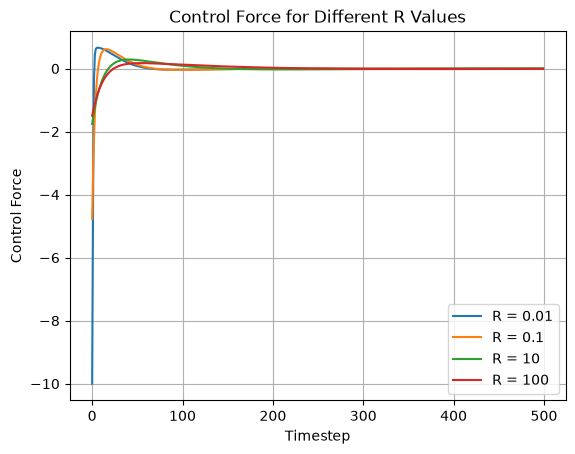

In [5]:
args = cartpole_lqr.parse_args(["--mode", "multiple_R"])

forces = cartpole_lqr.main(args)

for r_value, force_list in forces.items():
    plt.plot(force_list, label=f"R = {r_value}")

plt.xlabel("Timestep")
plt.ylabel("Control Force")
plt.title("Control Force for Different R Values")
plt.legend()
plt.grid()
plt.show()

### Question 1:
 Analyzing the plot, how does the choice of R affect the force? Are they proportional or inversely proportional?


### Answer 1:

Analyzing the plot, smaller values of R generally lead to faster responses and stabilization, but also require greater control effort, as the controller penalizes the use of control inputs less. Conversely, larger values of R result in smaller control forces and a more conservative response, potentially leading to slower stabilization.

# 4. Reinforcement Learning
The provided Python script (cartpole_rl.py) instantiates a Cartpole environment and a RL agent that acts on it. The agent.py file contains the implementation of a simple reinforcement learning agent; for the sake of this exercise, you can assume it to be a black box (you don’t need to understand how it works, although you are encouraged to study it in more detail). You don’t have to edit that file to complete this exercise session - all changes should be done in cartpole_rl.py.





## 4.1 Training and testing
Run the cartpole_rl.py script. See how it learns to balance the pole after training for some amount of episodes. You can use the --render_training argument to visualize the training (it will run slower when rendering).
When the training is finished, the models are saved to CartPole-v0_params.ai and can be tested by passing --test <path>/<to>/<model>/<file.ai>. You can use the --render_test argument here.

All the training algorithm is encapsulated within the train(...) function. Examine the training loop and answer the following questions:

In [6]:
import cartpole_rl
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 20 (20 timesteps)
Episode 1 finished. Total reward: 17 (17 timesteps)
Episode 2 finished. Total reward: 11 (11 timesteps)
Episode 3 finished. Total reward: 19 (19 timesteps)
Episode 4 finished. Total reward: 12 (12 timesteps)
Episode 5 finished. Total reward: 19 (19 timesteps)
Episode 6 finished. Total reward: 27 (27 timesteps)
Episode 7 finished. Total reward: 12 (12 timesteps)
Episode 8 finished. Total reward: 27 (27 timesteps)
Episode 9 finished. Total reward: 35 (35 timesteps)
Episode 10 finished. Total reward: 20 (20 timesteps)
Episode 11 finished. Total reward: 23 (23 timesteps)
Episode 12 finished. Total reward: 48 (48 timesteps)
Episode 13 finished. Total reward: 39 (39 timesteps)
Episode 14 finished. Total reward: 19 (19 timesteps)
Episode 15 finished. Total reward: 22 (22 timesteps)
Episode 16 finished. Total reward: 21 (21 timesteps)
Epis

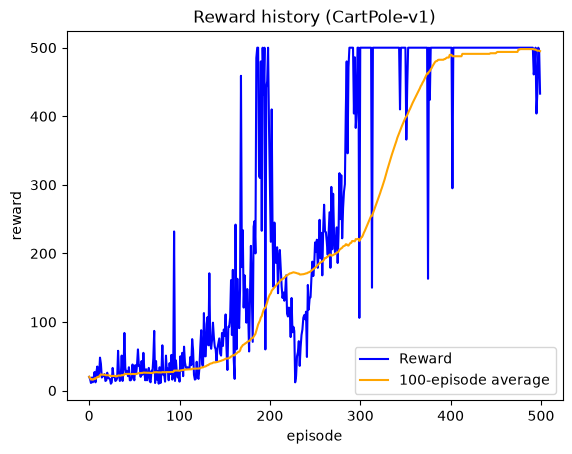

Training finished.


In [7]:
args = cartpole_rl.parse_args(["--file","CartPole-v0_params.ai"])
training_history_agent = cartpole_rl.main(args)

In [8]:
args = cartpole_rl.parse_args(["--test", "CartPole-v0_params.ai"])
training_history_agent = cartpole_rl.main(args)

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-v0_params.ai ...
Testing...
Num testing episodes: 10
Average test reward: 368.2 episode length: 368.2


### Question 1.0.1
What are the conditions under which the episode ends? Do all episodes conclude at the same timestep?


### Answer 1.0.1:


An episode terminates when the pole angle exceeds 12° or the cart position moves beyond 2.4 units from the center, which counts as a failure to balance the pole. Otherwise, the episode is truncated after 500 timesteps.

No, they don't finish at the sime timestep.

### Question 1.0.2
How is the reward internally computed?

*Note: You can refer to the environment's documentation for more details or inspect the code to
determine when different episodes conclude. Rendering the environment may also aid in
understanding episode termination and reward computation.*


### Answer 1.0.2:

At each timestep, the environment provides a reward of +1 as long as the episode has not terminated or been truncated. Therefore, the total episode reward corresponds to the number of timesteps the cartpole remains balanced.

## Task 1.1.
Try to train the agent using a random policy. This entails not considering the predicted actions by the agent at each current timestep. Instead, sample a random action from within the action space, and perform this action on the environment.

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 12 (12 timesteps)
Episode 1 finished. Total reward: 14 (14 timesteps)
Episode 2 finished. Total reward: 41 (41 timesteps)
Episode 3 finished. Total reward: 20 (20 timesteps)
Episode 4 finished. Total reward: 17 (17 timesteps)
Episode 5 finished. Total reward: 20 (20 timesteps)
Episode 6 finished. Total reward: 16 (16 timesteps)
Episode 7 finished. Total reward: 22 (22 timesteps)
Episode 8 finished. Total reward: 17 (17 timesteps)
Episode 9 finished. Total reward: 31 (31 timesteps)
Episode 10 finished. Total reward: 22 (22 timesteps)
Episode 11 finished. Total reward: 23 (23 timesteps)
Episode 12 finished. Total reward: 10 (10 timesteps)
Episode 13 finished. Total reward: 24 (24 timesteps)
Episode 14 finished. Total reward: 22 (22 timesteps)
Episode 15 finished. Total reward: 17 (17 timesteps)
Episode 16 finished. Total reward: 17 (17 timesteps)
Epis

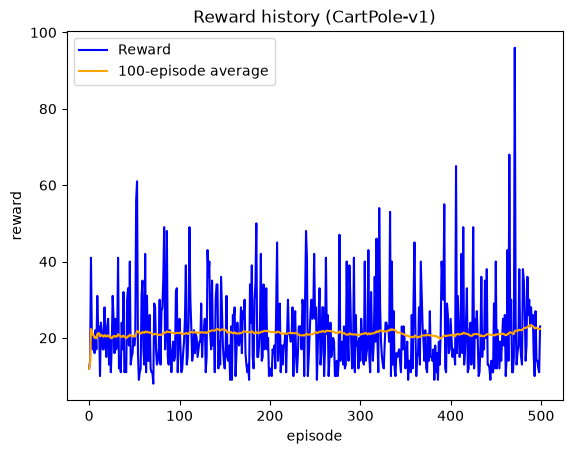

Training finished.


In [9]:
args = cartpole_rl.parse_args(["--random_policy","--file","CartPole-random_params.ai"])
training_history_random = cartpole_rl.main(args)

In [10]:
args = cartpole_rl.parse_args(["--test", "CartPole-random_params.ai"])
training_history_agent = cartpole_rl.main(args)

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-random_params.ai ...
Testing...
Num testing episodes: 10
Average test reward: 65.6 episode length: 65.6


### Question 1.1
Evaluate the learned random policy. What is the performance in terms of the average test reward compared to training with the normal policy? Briefly analyze the underlying causes.


### Answer 1.1:

The random policy performs worse than the original training algorithm because it does not use the agent's experience to improve its actions. Instead, it selects a random action at each timestep, independently of the observed state. Consequently, the agent cannot learn an effective control strategy during training, resulting in poorer performance during testing. In our experiment, the random-policy-trained agent achieved an average test reward of approximately 110 points, whereas the original training algorithm achieved approximately 500 points.

## Task 1.2
Train the agent using the Reinforcement Learning policy with up to 200 timesteps per episode. First, tune the learning rate hyperparameter, as this can have a significant impact on the policy's performance. Try values from the following range:

[1e-5, 1e-4, 1e-3, 1e-2, 1e-1].


Training with learning rate = 1e-05
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 15 (15 timesteps)
Episode 1 finished. Total reward: 14 (14 timesteps)
Episode 2 finished. Total reward: 17 (17 timesteps)
Episode 3 finished. Total reward: 11 (11 timesteps)
Episode 4 finished. Total reward: 17 (17 timesteps)
Episode 5 finished. Total reward: 35 (35 timesteps)
Episode 6 finished. Total reward: 13 (13 timesteps)
Episode 7 finished. Total reward: 22 (22 timesteps)
Episode 8 finished. Total reward: 31 (31 timesteps)
Episode 9 finished. Total reward: 21 (21 timesteps)
Episode 10 finished. Total reward: 26 (26 timesteps)
Episode 11 finished. Total reward: 31 (31 timesteps)
Episode 12 finished. Total reward: 11 (11 timesteps)
Episode 13 finished. Total reward: 10 (10 timesteps)
Episode 14 finished. Total reward: 18 (18 timesteps)
Episode 15 finished. Total reward: 18 (18 timesteps)
Episode 16 finished.

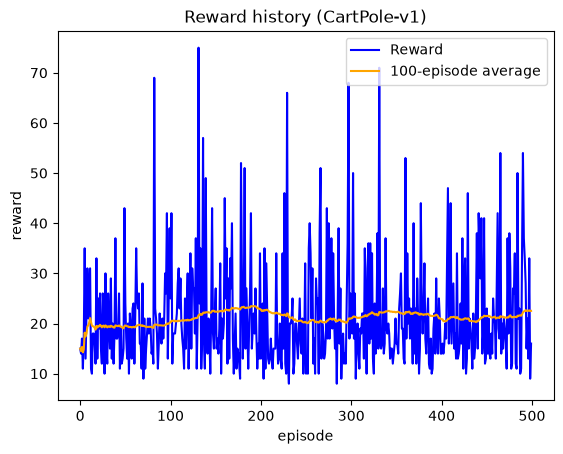

Training finished.

Training with learning rate = 0.0001
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 10 (10 timesteps)
Episode 1 finished. Total reward: 27 (27 timesteps)
Episode 2 finished. Total reward: 17 (17 timesteps)
Episode 3 finished. Total reward: 16 (16 timesteps)
Episode 4 finished. Total reward: 27 (27 timesteps)
Episode 5 finished. Total reward: 14 (14 timesteps)
Episode 6 finished. Total reward: 38 (38 timesteps)
Episode 7 finished. Total reward: 21 (21 timesteps)
Episode 8 finished. Total reward: 14 (14 timesteps)
Episode 9 finished. Total reward: 12 (12 timesteps)
Episode 10 finished. Total reward: 11 (11 timesteps)
Episode 11 finished. Total reward: 24 (24 timesteps)
Episode 12 finished. Total reward: 10 (10 timesteps)
Episode 13 finished. Total reward: 20 (20 timesteps)
Episode 14 finished. Total reward: 18 (18 timesteps)
Episode 15 finished. Total reward: 28 (28 timesteps)


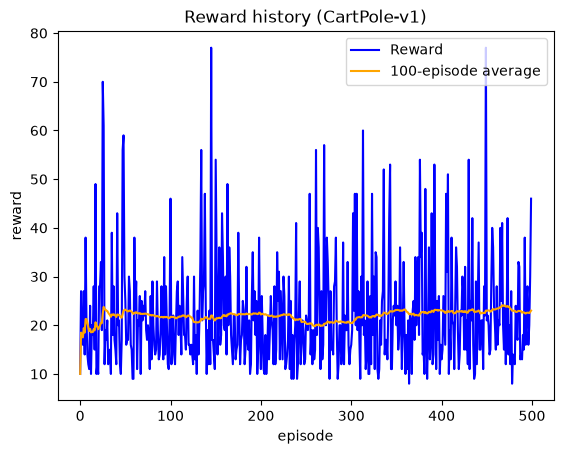

Training finished.

Training with learning rate = 0.001
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 17 (17 timesteps)
Episode 1 finished. Total reward: 13 (13 timesteps)
Episode 2 finished. Total reward: 32 (32 timesteps)
Episode 3 finished. Total reward: 61 (61 timesteps)
Episode 4 finished. Total reward: 14 (14 timesteps)
Episode 5 finished. Total reward: 16 (16 timesteps)
Episode 6 finished. Total reward: 12 (12 timesteps)
Episode 7 finished. Total reward: 21 (21 timesteps)
Episode 8 finished. Total reward: 13 (13 timesteps)
Episode 9 finished. Total reward: 18 (18 timesteps)
Episode 10 finished. Total reward: 21 (21 timesteps)
Episode 11 finished. Total reward: 18 (18 timesteps)
Episode 12 finished. Total reward: 17 (17 timesteps)
Episode 13 finished. Total reward: 22 (22 timesteps)
Episode 14 finished. Total reward: 13 (13 timesteps)
Episode 15 finished. Total reward: 19 (19 timesteps)
E

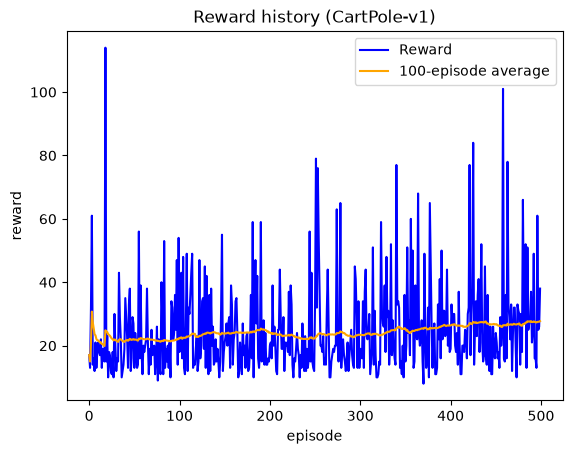

Training finished.

Training with learning rate = 0.01
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 30 (30 timesteps)
Episode 1 finished. Total reward: 11 (11 timesteps)
Episode 2 finished. Total reward: 14 (14 timesteps)
Episode 3 finished. Total reward: 16 (16 timesteps)
Episode 4 finished. Total reward: 17 (17 timesteps)
Episode 5 finished. Total reward: 46 (46 timesteps)
Episode 6 finished. Total reward: 26 (26 timesteps)
Episode 7 finished. Total reward: 10 (10 timesteps)
Episode 8 finished. Total reward: 18 (18 timesteps)
Episode 9 finished. Total reward: 26 (26 timesteps)
Episode 10 finished. Total reward: 18 (18 timesteps)
Episode 11 finished. Total reward: 33 (33 timesteps)
Episode 12 finished. Total reward: 29 (29 timesteps)
Episode 13 finished. Total reward: 32 (32 timesteps)
Episode 14 finished. Total reward: 23 (23 timesteps)
Episode 15 finished. Total reward: 26 (26 timesteps)
Ep

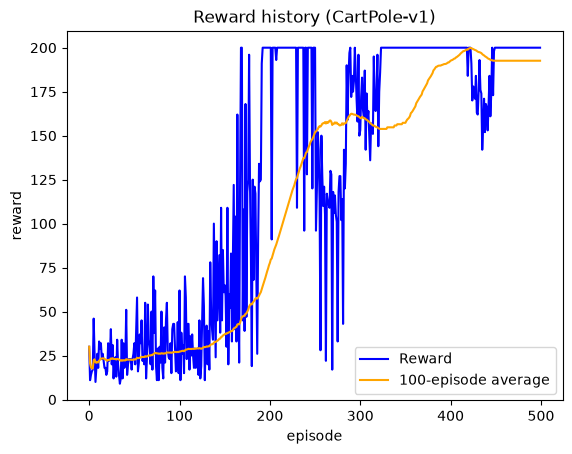

Training finished.

Training with learning rate = 0.1
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 10 (10 timesteps)
Episode 1 finished. Total reward: 61 (61 timesteps)
Episode 2 finished. Total reward: 14 (14 timesteps)
Episode 3 finished. Total reward: 19 (19 timesteps)
Episode 4 finished. Total reward: 21 (21 timesteps)
Episode 5 finished. Total reward: 63 (63 timesteps)
Episode 6 finished. Total reward: 58 (58 timesteps)
Episode 7 finished. Total reward: 17 (17 timesteps)
Episode 8 finished. Total reward: 70 (70 timesteps)
Episode 9 finished. Total reward: 23 (23 timesteps)
Episode 10 finished. Total reward: 39 (39 timesteps)
Episode 11 finished. Total reward: 45 (45 timesteps)
Episode 12 finished. Total reward: 61 (61 timesteps)
Episode 13 finished. Total reward: 93 (93 timesteps)
Episode 14 finished. Total reward: 61 (61 timesteps)
Episode 15 finished. Total reward: 62 (62 timesteps)
Epi

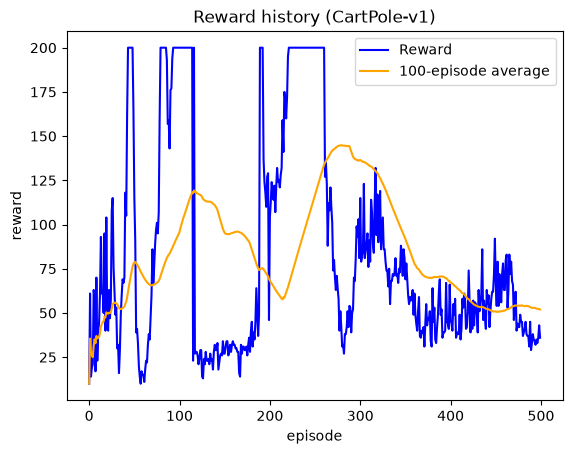

Training finished.


In [11]:
learning_rates = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
training_histories = {}

for lr in learning_rates:
    print(f"\nTraining with learning rate = {lr}")
    args = cartpole_rl.parse_args([
        "--learning_rate", str(lr),
        "--train_episodes", "500",
        "--episode_length", "200",
        "--file", f"CartPole-lr{lr}_params.ai"
    ])
    training_history = cartpole_rl.main(args)
    training_histories[lr] = training_history

### Question 1.2:
Which learning rate value provides the best, most stable performance? Can you explain why?

Learning rate = 0.01 provides the best and most stable performance, as with smaller learning rates (<0.01) the model converges too slowly to reach optimal performance within the  episodes or gets trapped in local minima. Larger learning rates (> 0.01) cause oversized parameter updates. This leads the optimization process to continuously overshoot the minimum, resulting in high variance across episodes, training instability, or gradient divergence. Thus, learning rate = 0.01 strikes the ideal trade-off between steady convergence speed and stability.

## Task 1.3
Then test the model for 500 timesteps by
changing line n.138 in cartpole_rl.py. You can test the model with:


```
python cartpole_rl.py -t <MODELFILE> --render_test
```

<br>

*Note: the episode length and the number of episodes given by the command line argument
train_episodes are two different things. If you include plots in your submission, use the
train_episodes  as their x-axis.*


In [12]:
lr = 1e-2

#test for 500 timesteps
args = cartpole_rl.parse_args(["--test", f"CartPole-lr{lr}_params.ai", "--episode_length", "500"])
training_history_agent = cartpole_rl.main(args)

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-lr0.01_params.ai ...
Testing...
Num testing episodes: 10
Average test reward: 334.8 episode length: 334.8


### Question 1.3:
Can the same model, trained to balance for 200 timesteps, also balance the pole
for 500 timesteps? Briefly justify your answer.


### Answer 1.3:

As we saw in the computer simulation, yes. The model's policy selects actions based entirely on the system's current state and because the model was trained to stabilize the system around an equilibrium point, maintaining state stability for 200 timesteps demonstrates that it has learned a steady control loop. Provided the state remains within the safe region of the state space, the same policy can continue to keep the pole balanced for 500 timesteps (or longer).

## Task 1.4:
 Repeat the experiment a few times, each time training the model from scratch with 200
timesteps and testing it for 500 timesteps. Evaluate its performance by using the --render_test argument and remember the average test rewards.



Experiment 1: training with learning rate = 0.01
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 45 (45 timesteps)
Episode 1 finished. Total reward: 15 (15 timesteps)
Episode 2 finished. Total reward: 25 (25 timesteps)
Episode 3 finished. Total reward: 16 (16 timesteps)
Episode 4 finished. Total reward: 19 (19 timesteps)
Episode 5 finished. Total reward: 30 (30 timesteps)
Episode 6 finished. Total reward: 16 (16 timesteps)
Episode 7 finished. Total reward: 43 (43 timesteps)
Episode 8 finished. Total reward: 51 (51 timesteps)
Episode 9 finished. Total reward: 13 (13 timesteps)
Episode 10 finished. Total reward: 50 (50 timesteps)
Episode 11 finished. Total reward: 32 (32 timesteps)
Episode 12 finished. Total reward: 21 (21 timesteps)
Episode 13 finished. Total reward: 28 (28 timesteps)
Episode 14 finished. Total reward: 18 (18 timesteps)
Episode 15 finished. Total reward: 22 (22 timesteps)
Episode

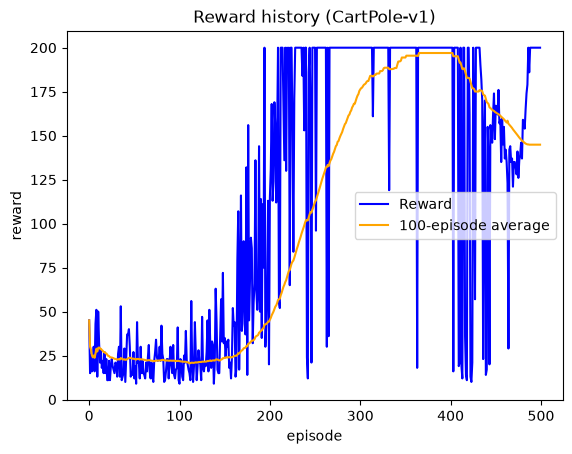

Training finished.
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-v1_params.ai ...
Testing...
Num testing episodes: 10
Average test reward: 417.1 episode length: 417.1
Average test reward: 417.1

Experiment 2: training with learning rate = 0.01
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 25 (25 timesteps)
Episode 1 finished. Total reward: 18 (18 timesteps)
Episode 2 finished. Total reward: 17 (17 timesteps)
Episode 3 finished. Total reward: 20 (20 timesteps)
Episode 4 finished. Total reward: 16 (16 timesteps)
Episode 5 finished. Total reward: 21 (21 timesteps)
Episode 6 finished. Total reward: 19 (19 timesteps)
Episode 7 finished. Total reward: 17 (17 timesteps)
Episode 8 finished. Total reward: 31 (31 timesteps)
Episode 9 finished. Total reward: 36 (36 timesteps)
Episode 10 finished. Total reward: 13 (13 ti

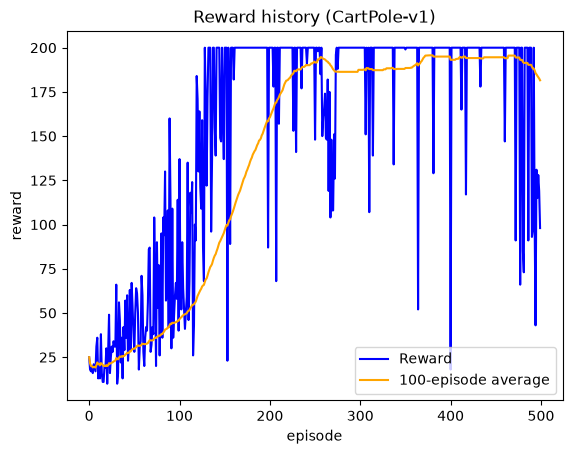

Training finished.
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-v1_params.ai ...
Testing...
Num testing episodes: 10
Average test reward: 110.8 episode length: 110.8
Average test reward: 110.8

Experiment 3: training with learning rate = 0.01
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 11 (11 timesteps)
Episode 1 finished. Total reward: 11 (11 timesteps)
Episode 2 finished. Total reward: 21 (21 timesteps)
Episode 3 finished. Total reward: 23 (23 timesteps)
Episode 4 finished. Total reward: 11 (11 timesteps)
Episode 5 finished. Total reward: 38 (38 timesteps)
Episode 6 finished. Total reward: 24 (24 timesteps)
Episode 7 finished. Total reward: 12 (12 timesteps)
Episode 8 finished. Total reward: 13 (13 timesteps)
Episode 9 finished. Total reward: 17 (17 timesteps)
Episode 10 finished. Total reward: 16 (16 ti

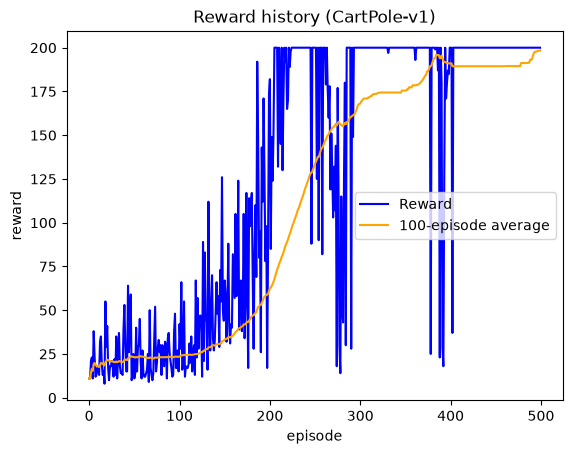

Training finished.
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-v1_params.ai ...
Testing...
Num testing episodes: 10
Average test reward: 500.0 episode length: 500.0
Average test reward: 500.0

Experiment 4: training with learning rate = 0.01
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 11 (11 timesteps)
Episode 1 finished. Total reward: 13 (13 timesteps)
Episode 2 finished. Total reward: 18 (18 timesteps)
Episode 3 finished. Total reward: 18 (18 timesteps)
Episode 4 finished. Total reward: 13 (13 timesteps)
Episode 5 finished. Total reward: 44 (44 timesteps)
Episode 6 finished. Total reward: 25 (25 timesteps)
Episode 7 finished. Total reward: 39 (39 timesteps)
Episode 8 finished. Total reward: 15 (15 timesteps)
Episode 9 finished. Total reward: 16 (16 timesteps)
Episode 10 finished. Total reward: 37 (37 ti

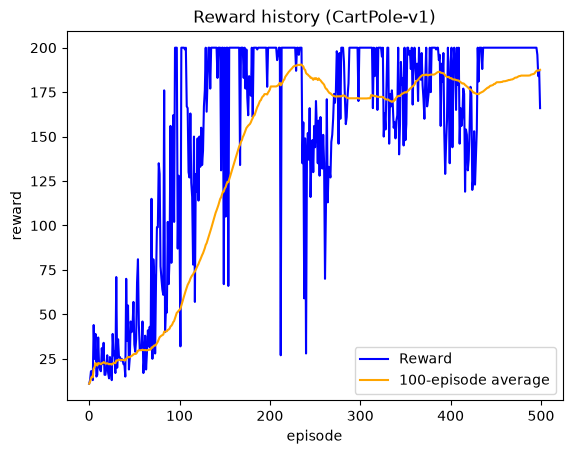

Training finished.
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-v1_params.ai ...
Testing...
Num testing episodes: 10
Average test reward: 172.3 episode length: 172.3
Average test reward: 172.3

Experiment 5: training with learning rate = 0.01
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 15 (15 timesteps)
Episode 1 finished. Total reward: 16 (16 timesteps)
Episode 2 finished. Total reward: 32 (32 timesteps)
Episode 3 finished. Total reward: 11 (11 timesteps)
Episode 4 finished. Total reward: 11 (11 timesteps)
Episode 5 finished. Total reward: 18 (18 timesteps)
Episode 6 finished. Total reward: 55 (55 timesteps)
Episode 7 finished. Total reward: 27 (27 timesteps)
Episode 8 finished. Total reward: 10 (10 timesteps)
Episode 9 finished. Total reward: 24 (24 timesteps)
Episode 10 finished. Total reward: 15 (15 ti

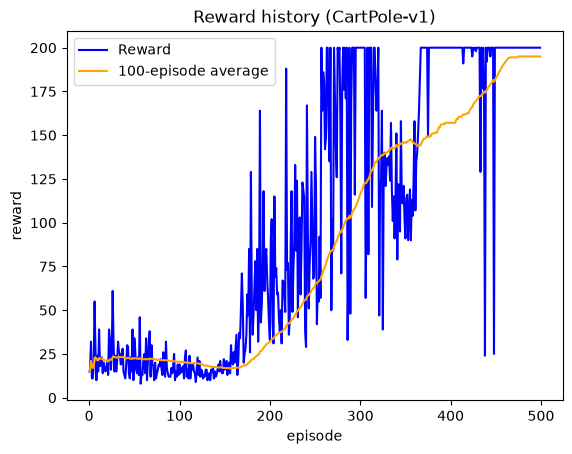

Training finished.
Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-v1_params.ai ...
Testing...
Num testing episodes: 10
Average test reward: 500.0 episode length: 500.0
Average test reward: 500.0
Mean test reward: 340.04
Standard deviation: 166.01224774094229


In [15]:
import importlib
importlib.reload(cartpole_rl)
learning_rates = [1e-2]
n_experiments = 5

experiment_results = {}
training_histories = {}

for exp in range(1, n_experiments + 1):
    for lr in learning_rates:
        print(f"\nExperiment {exp}: training with learning rate = {lr}")
        # Training from scratch: 200 timesteps per episode
        args = cartpole_rl.parse_args([ "--learning_rate", str(lr),"--train_episodes", "500","--episode_length", "200"])
        training_history = cartpole_rl.main(args)
        training_histories[(exp, lr)] = training_history
        # Testing: 500 timesteps per episode
        args = cartpole_rl.parse_args(["--test", "CartPole-v1_params.ai", "--episode_length", "500","--test_episodes", "10"])#,"--render_test"])

        cartpole_rl.main(args)

        average_test_reward = cartpole_rl.last_test_reward
        experiment_results[(exp, lr)] = average_test_reward

        print(f"Average test reward: {average_test_reward}")


results = list(experiment_results.values())

print("Mean test reward:", np.mean(results))
print("Standard deviation:", np.std(results))

In [16]:
print(results)

[417.1, 110.8, 500.0, 172.3, 500.0]


### Question 1.4:
Are the behavior and performance of the trained model the same every time?
Analyze the causes briefly.


### Answer 1.4:

No, the models are not identical. Even under identical evaluation conditions they differ in stability and total reward mainly because of training randomness, train/test horizon mismatch and initial-state noise. 

# 4.2 Repeatability

Figure 2 shows the mean and standard deviation throughout 100 independent training procedures. You can notice that there is a large variance between the runs of the script.

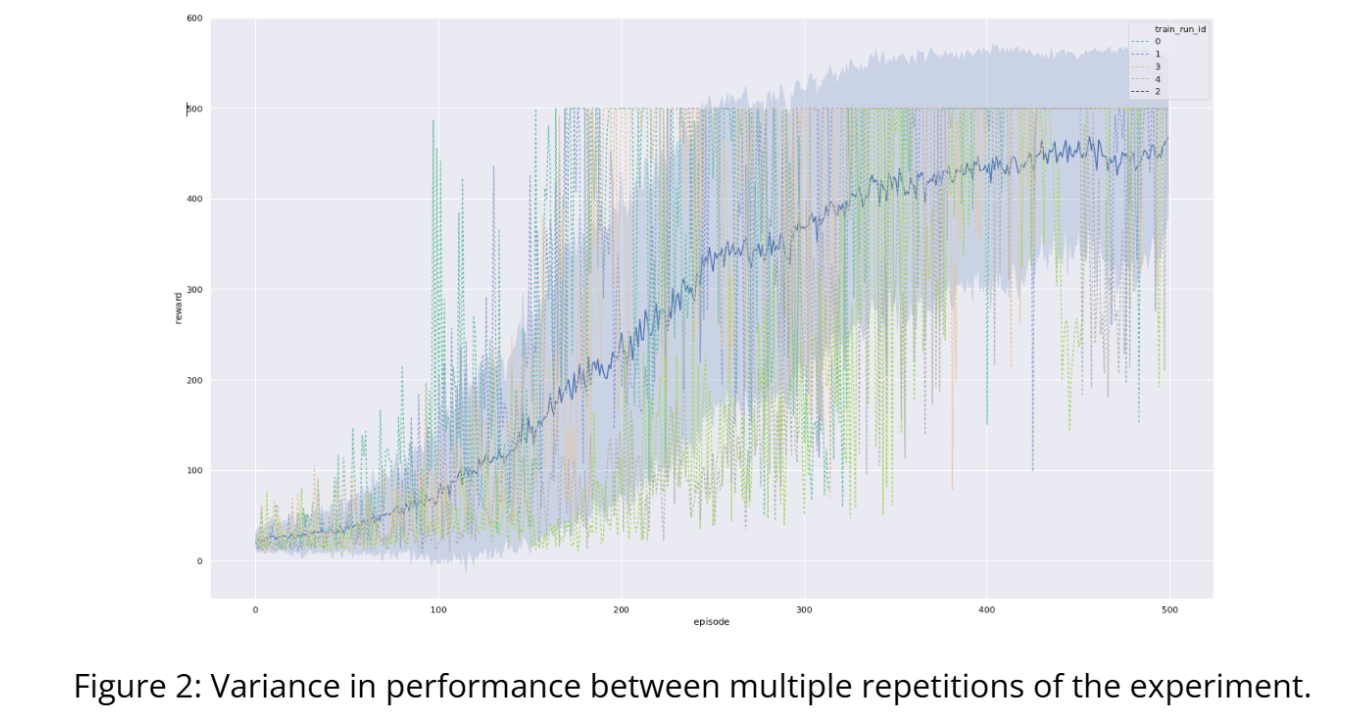

### Question 2:
Why is this the case? What are the implications of this stochasticity, when it comes to comparing reinforcement learning algorithms to each other? Please explain.

*Note: You can generate a similar plot by running the multiple_cartpoles_rl.py script. If the script is slow, try disabling PyTorch multithreading (by running the script with OMP_NUM_THREADS=1)*



### Answer 2:

The large variance between independent training procedures results from the stochastic nature of reinforcement learning, where randomness arises from policy initialization, action selection, and trajectory sampling. Additionally, REINFORCE uses sampled returns to estimate policy gradients, leading to high-variance parameter updates and potentially unstable learning. Consequently, different runs may follow significantly different learning paths, even with identical hyperparameters. This stochasticity makes comparisons between RL algorithms challenging, as a single run cannot reliably represent an algorithm's performance. Therefore, algorithms should be evaluated over multiple independent runs, comparing their mean performance and standard deviation, as well as their sample efficiency, learning stability, and final performance.

# 4.3 Reward functions:
Let us design a custom reward function and use it instead of the default reward returned by the environment (see the new_reward(...) function for an example).




## Task 3.1
Write different reward functions to incentivise the agent to learn the following behaviors and include them in your report:
1. Balance the pole close to the center of the screen (close to x=0),
2. Balance the pole in an arbitrary point of the screen (x=x0), with x0 passed as a command line argument to the script,
3. Keep the cart moving from the leftmost to rightmost side of the track as fast as possible, while still balancing the pole. The minimum speed of the agent should be high enough that the agent is visibly moving from one side of the other (not just jittering in the center) and changes direction at least once and not just drifting in a random direction.

Train a model with each reward function and include them in your submission.

**Hint**: Use the observation vector to get the quantities required to compute the new reward (such as the
speed and position of the cart). If you feel like your model needs more time to train, you can leave it running for longer with the command line argument --train_episodes number, where number is the amount of episodes the model will be trained for (default is 500).



In [17]:
import cartpole_rl
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 29.4 (20 timesteps)
Episode 1 finished. Total reward: 26.3 (18 timesteps)
Episode 2 finished. Total reward: 24.9 (17 timesteps)
Episode 3 finished. Total reward: 20.4 (14 timesteps)
Episode 4 finished. Total reward: 26.7 (18 timesteps)
Episode 5 finished. Total reward: 26.4 (18 timesteps)
Episode 6 finished. Total reward: 62.2 (42 timesteps)
Episode 7 finished. Total reward: 71.9 (50 timesteps)
Episode 8 finished. Total reward: 14.8 (10 timesteps)
Episode 9 finished. Total reward: 19.3 (13 timesteps)
Episode 10 finished. Total reward: 22.2 (15 timesteps)
Episode 11 finished. Total reward: 52.9 (36 timesteps)
Episode 12 finished. Total reward: 63.6 (44 timesteps)
Episode 13 finished. Total reward: 25.1 (17 timesteps)
Episode 14 finished. Total reward: 22.2 (15 timesteps)
Episode 15 finished. Total reward: 20.7 (14 timesteps)
Episode 16 finished. Tota

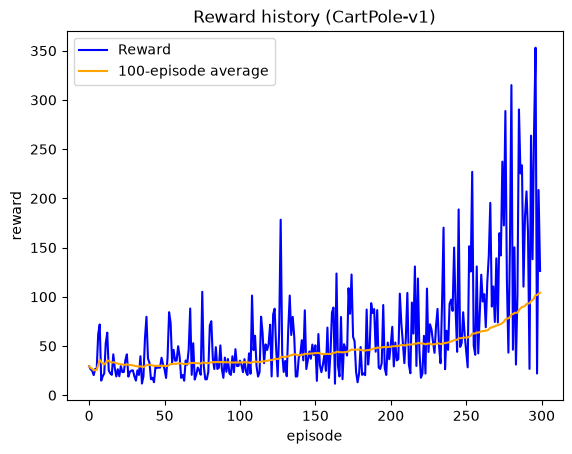

Training finished.


In [18]:
# Training #CASE1
args = cartpole_rl.parse_args(["--train_episodes", "300","--episode_length", "500", "--reward", "CASE1","--file","CartPole-CASE1-reward_params.ai"])
training_history = cartpole_rl.main(args)

In [19]:
args = cartpole_rl.parse_args(["--test", "CartPole-CASE1-reward_params.ai", "--episode_length", "500",
                               "--test_episodes", "10","--reward", "CASE1",])
cartpole_rl.main(args)

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-CASE1-reward_params.ai ...
Testing...
Num testing episodes: 10
Average test reward: 438.97852 episode length: 322.8


##### Case 2

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 13.4 (10 timesteps)
Episode 1 finished. Total reward: 41.2 (31 timesteps)
Episode 2 finished. Total reward: 26.9 (20 timesteps)
Episode 3 finished. Total reward: 25.3 (19 timesteps)
Episode 4 finished. Total reward: 26.8 (20 timesteps)
Episode 5 finished. Total reward: 18.9 (14 timesteps)
Episode 6 finished. Total reward: 22.8 (17 timesteps)
Episode 7 finished. Total reward: 47.6 (36 timesteps)
Episode 8 finished. Total reward: 32.2 (24 timesteps)
Episode 9 finished. Total reward: 20.1 (15 timesteps)
Episode 10 finished. Total reward: 16.1 (12 timesteps)
Episode 11 finished. Total reward: 63 (48 timesteps)
Episode 12 finished. Total reward: 18.7 (14 timesteps)
Episode 13 finished. Total reward: 20.1 (15 timesteps)
Episode 14 finished. Total reward: 16 (12 timesteps)
Episode 15 finished. Total reward: 17.3 (13 timesteps)
Episode 16 finished. Total re

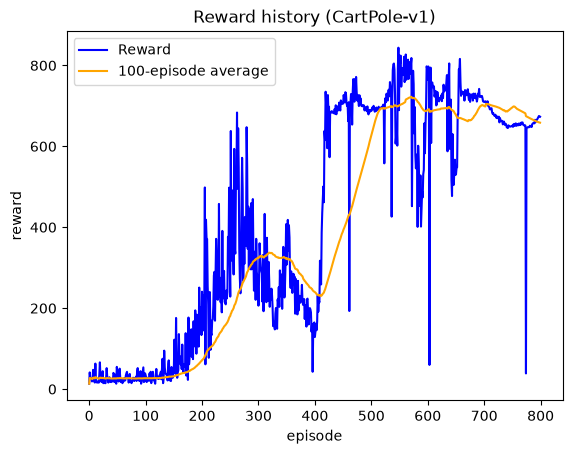

Training finished.


In [20]:
# Training #CASE2
import importlib
importlib.reload(cartpole_rl)

args = cartpole_rl.parse_args(["--train_episodes", "800","--episode_length", "500", "--reward", 
"CASE2","--file","CartPole-CASE2-reward_params.ai", "--central_point", "-2"])
training_history = cartpole_rl.main(args)

In [21]:
args = cartpole_rl.parse_args(["--test", "CartPole-CASE2-reward_params.ai", "--episode_length", "500",
"--test_episodes", "1","--reward", "CASE2","--render_test"])
cartpole_rl.main(args)
#Corrigir "Average test rewaard", igual para todos os casos...

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-CASE2-reward_params.ai ...
Testing...
Num testing episodes: 1
Average test reward: 914.1081 episode length: 500.0


##### Case 3

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Episode 0 finished. Total reward: 15.7 (14 timesteps)
Episode 1 finished. Total reward: 20.9 (21 timesteps)
Episode 2 finished. Total reward: 34.5 (28 timesteps)
Episode 3 finished. Total reward: 36.9 (31 timesteps)
Episode 4 finished. Total reward: 21.7 (21 timesteps)
Episode 5 finished. Total reward: 40.3 (40 timesteps)
Episode 6 finished. Total reward: 20 (17 timesteps)
Episode 7 finished. Total reward: 57.6 (52 timesteps)
Episode 8 finished. Total reward: 14.5 (10 timesteps)
Episode 9 finished. Total reward: 15.8 (12 timesteps)
Episode 10 finished. Total reward: 31.9 (29 timesteps)
Episode 11 finished. Total reward: 25.7 (21 timesteps)
Episode 12 finished. Total reward: 15 (13 timesteps)
Episode 13 finished. Total reward: 24.2 (19 timesteps)
Episode 14 finished. Total reward: 15.2 (12 timesteps)
Episode 15 finished. Total reward: 33.5 (28 timesteps)
Episode 16 finished. Total re

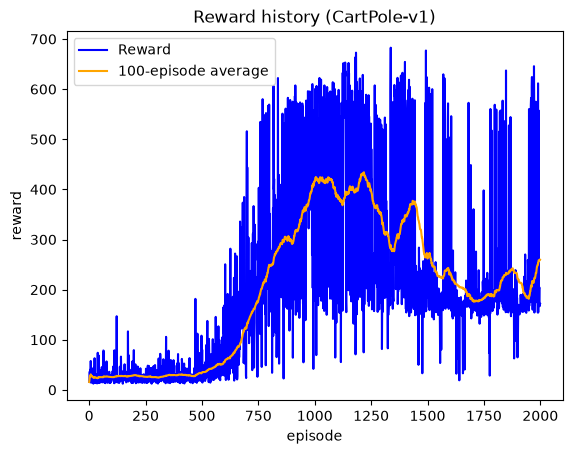

Training finished.


In [22]:
# Training #CASE3
import importlib
import cartpole_rl 
importlib.reload(cartpole_rl)
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

args = cartpole_rl.parse_args(["--train_episodes", "2000","--episode_length", "500", 
                               "--reward", "CASE3","--file","CartPole-CASE3-reward_params.ai","--learning_rate","1.5e-3"])
training_history = cartpole_rl.main(args)

In [28]:
import cartpole_rl
import importlib 
importlib.reload(cartpole_rl)
args = cartpole_rl.parse_args(["--test", "CartPole-CASE3-reward_params.ai", 
"--reward", "CASE3",
"--episode_length", "1200",
"--test_episodes", "1",
"--render_test"])

cartpole_rl.main(args)

Environment: CartPole-v1
Training device: cpu
Observation space dimensions: 4
Action space dimensions: 2
Loading model from CartPole-CASE3-reward_params.ai ...
Testing...
Num testing episodes: 1
Average test reward: 1142.6083307206627 episode length: 962.0


##### The first and the second reward implementations led to the desired behavior in the test episodes. Reward 3, which tried to increase the velocity near the center and push the cart back toward the center at the borders (emulating SHM), did not work completely: the agent learned an oscillatory movement, which attends to the challange, but it wasn't stable enough to avoid falling.

## Task 3.2
Let us visualize the third reward function. Train the model at least 10 times using
multiple_cartpoles_rl.py (adjust the --num_runs and --train_episodes parameters) and include the performance plots similar to Fig. 2.


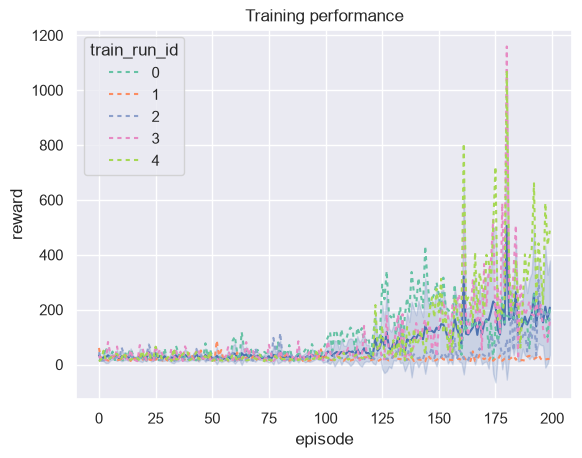

In [ ]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import torch
torch.set_num_threads(1)

import multiple_cartpoles_rl

args = multiple_cartpoles_rl.parse_args([
"--reward", "CASE3",
"--episode_steps", "1000",
"--train_episodes", "200",
"--num_runs", "10",
"--test", ""])

multiple_cartpoles_rl.main(args)

### Question 3.2:
Observe the agent using `python cartpole_rl.py -t <MODELFILE> --render_test` and keep track of the observations. What do you observe? What is the highest velocity the agent reaches?



In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import cartpole_rl

In [ ]:
args = cartpole_rl.parse_args([
"--test", "Multiple_agents_params.ai",
"--render_test"])

cartpole_rl.main(args)

### Answer 3.2

The cartpole doesn't act according to the goal, it mostly stays in the center (with very low velocity), differently from what was tested using the original model (without multiple agents).

# 5. Extras

### Question 1:
Discuss briefly the advantages of using an LQR controller or an RL agent to solve a general task of controlling a robotic system. Analyze the differences and similarities between the two methods.


### Answer 1:


Both methods rely on full observation of the system's state vector to calculate control actions, and both require manual tuning of design hyperparameters, such as the state and input cost weighting matrices (Q and R) in LQR, or the learning rate, discount factor, and reward function structure in RL. However, their underlying mechanics diverge significantly in model dependence and computation. LQR is a model-based analytical technique that requires an explicit, linearized mathematical model of the physical system (represented by matrices A and B) to calculate the optimal gain matrix instantaneously via the Riccati equation, bypassing the need for iterative trial-and-error. In contrast, model-free RL algorithms learn a control policy directly through interaction with the environment across multiple training episodes without requiring access to the explicit differential equations of the system. While RL does not need an analytical physical model to compute control inputs, setting up an effective RL agent still requires physical intuition to properly design the reward function and select meaningful state features. Furthermore, reinforcement learning offers greater flexibility in learning complex and potentially unconventional behaviors, as reward functions can be designed to encourage a wide range of actions and objectives. Such behaviors may require considerably more specialized modeling and controller design when using traditional analytical methods.